In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


tickers = {
    "Brent Crude": "BZ=F",
    "WTI Crude": "CL=F",
    "Henry Hub": "NG=F",  # USD/MMBtu
    "Dutch TTF": "TTF=F",  # EUR/MWh, Yahoo history starts Oct 2017
    "JKM LNG": "JKM=F",  # USD/MMBtu, thinly traded before ~2021

    "Gold": "GC=F",
    "S&P 500": "^GSPC",
    "UK FTSE 100": "^FTSE",
}

data = yf.download(list(tickers.values()), start="2016-10-01", end="2026-10-20")[
    "Close"
]
data = data.rename(columns={v: k for k, v in tickers.items()})

log_returns = np.log(data / data.shift(1)).dropna()

correlation_matrix = log_returns.corr()

print("--- Cross-Asset Correlation Matrix ---")
print(correlation_matrix.round(3))

annualized_volatility = log_returns.std() * np.sqrt(252)

print("\n--- Annualized Volatility (Risk) ---")
print(annualized_volatility.round(4))

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_37890/2131477547.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(list(tickers.values()), start="2016-10-01", end="2026-10-20")[
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scr

--- Cross-Asset Correlation Matrix ---
Ticker       Brent Crude  WTI Crude   Gold  JKM LNG  Henry Hub  Dutch TTF  \
Ticker                                                                      
Brent Crude        1.000      0.893  0.045    0.105      0.077      0.202   
WTI Crude          0.893      1.000  0.073    0.088      0.077      0.164   
Gold               0.045      0.073  1.000    0.019      0.017     -0.018   
JKM LNG            0.105      0.088  0.019    1.000      0.049      0.375   
Henry Hub          0.077      0.077  0.017    0.049      1.000      0.127   
Dutch TTF          0.202      0.164 -0.018    0.375      0.127      1.000   
UK FTSE 100        0.207      0.186  0.088   -0.070      0.031     -0.062   
S&P 500            0.190      0.177  0.102   -0.047      0.081     -0.023   

Ticker       UK FTSE 100  S&P 500  
Ticker                             
Brent Crude        0.207    0.190  
WTI Crude          0.186    0.177  
Gold               0.088    0.102  
JKM LNG   


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_37890/713508343.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  fx = yf.download("EURUSD=X", start="2016-10-01", end="2026-10-13")["Close"].squeeze()
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
[*********************100%***********************]  1 of 1 completed


--- Latest prices & spreads (USD/MMBtu) ---
Ticker      Henry Hub  Dutch TTF  JKM LNG  TTF - HH  JKM - HH  JKM - TTF
Date                                                                    
2026-10-13       3.28      28.64    26.27     25.36     22.99      -2.37
2026-10-14       3.20      28.62    26.39     25.42     23.19      -2.23
2026-10-15       3.24      28.38    26.53     25.15     23.30      -1.85
2026-10-16       3.12      28.75    29.92     25.63     26.81       1.18
2026-10-19       3.06      28.91    30.01     25.85     26.95       1.10


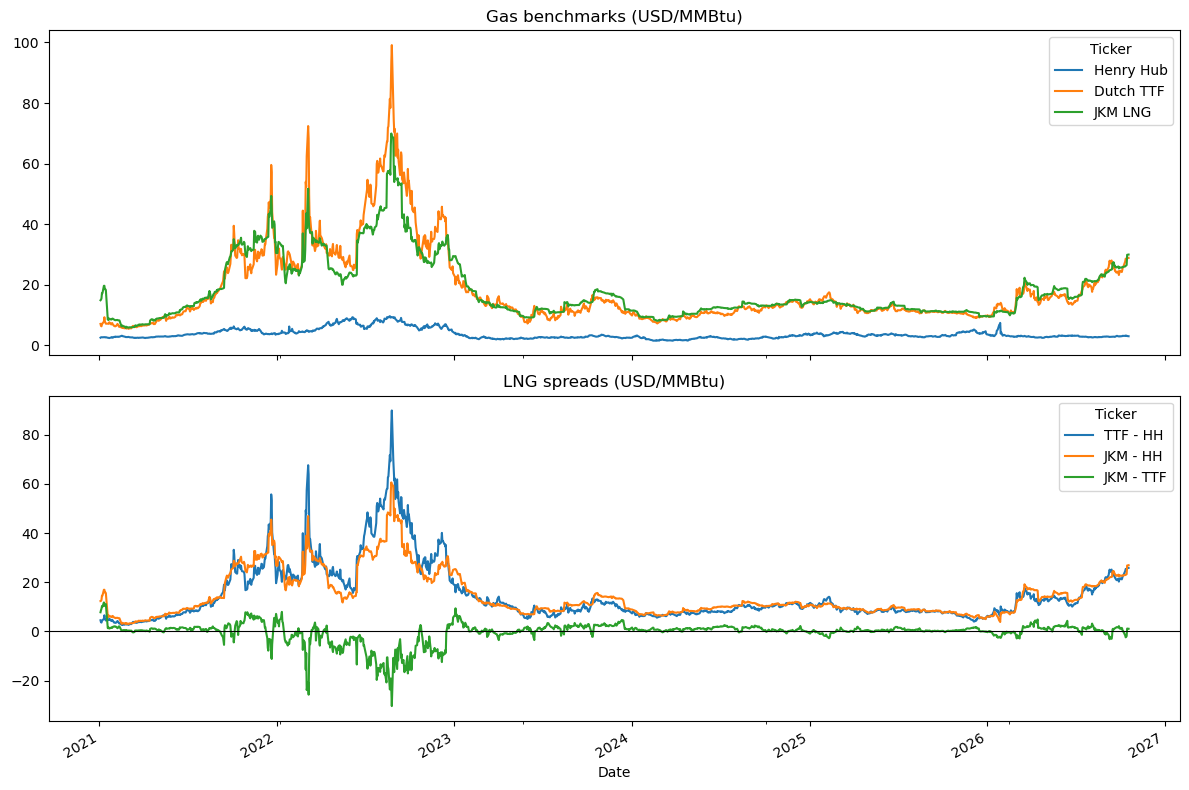

In [5]:
# LNG: put everything in USD/MMBtu so HH, TTF and JKM are comparable
# TTF is quoted in EUR/MWh -> convert with EURUSD and 1 MWh = 3.412 MMBtu
MWH_TO_MMBTU = 3.412

fx = yf.download("EURUSD=X", start="2016-10-01", end="2026-10-13")["Close"].squeeze()

gas = data[["Henry Hub", "Dutch TTF", "JKM LNG"]].copy()
gas["Dutch TTF"] = gas["Dutch TTF"] * fx.reindex(gas.index).ffill() / MWH_TO_MMBTU
gas = gas.loc["2021-01-01":].dropna()  # JKM history is patchy/stale before 2021

# Spreads: roughly the arb for US LNG exports (before liquefaction + shipping, ~$3-4/MMBtu)
gas["TTF - HH"] = gas["Dutch TTF"] - gas["Henry Hub"]
gas["JKM - HH"] = gas["JKM LNG"] - gas["Henry Hub"]
gas["JKM - TTF"] = gas["JKM LNG"] - gas["Dutch TTF"]  # Asia vs Europe competition for cargoes

print("--- Latest prices & spreads (USD/MMBtu) ---")
print(gas.tail(5).round(2))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
gas[["Henry Hub", "Dutch TTF", "JKM LNG"]].plot(ax=axes[0])
axes[0].set_title("Gas benchmarks (USD/MMBtu)")
gas[["TTF - HH", "JKM - HH", "JKM - TTF"]].plot(ax=axes[1])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("LNG spreads (USD/MMBtu)")
plt.tight_layout()
plt.show()


--- Latest netbacks (USD/MMBtu) ---
Date               2026-10-13  2026-10-14  2026-10-15  2026-10-16  2026-10-19
Ticker                                                                       
Henry Hub                3.28        3.20        3.24        3.12        3.06
Dutch TTF               28.64       28.62       28.38       28.75       28.91
JKM LNG                 26.27       26.39       26.53       29.92       30.01
Europe margin           23.47       23.54       23.26       23.77       23.99
Asia margin             19.99       20.21       20.31       23.84       23.99
Europe full-cycle       20.97       21.04       20.76       21.27       21.49
Asia full-cycle         17.49       17.71       17.81       21.34       21.49
Asia - Europe           -3.47       -3.33       -2.95        0.08       -0.00
z-score                 -2.89       -2.71       -2.47       -2.39       -2.34


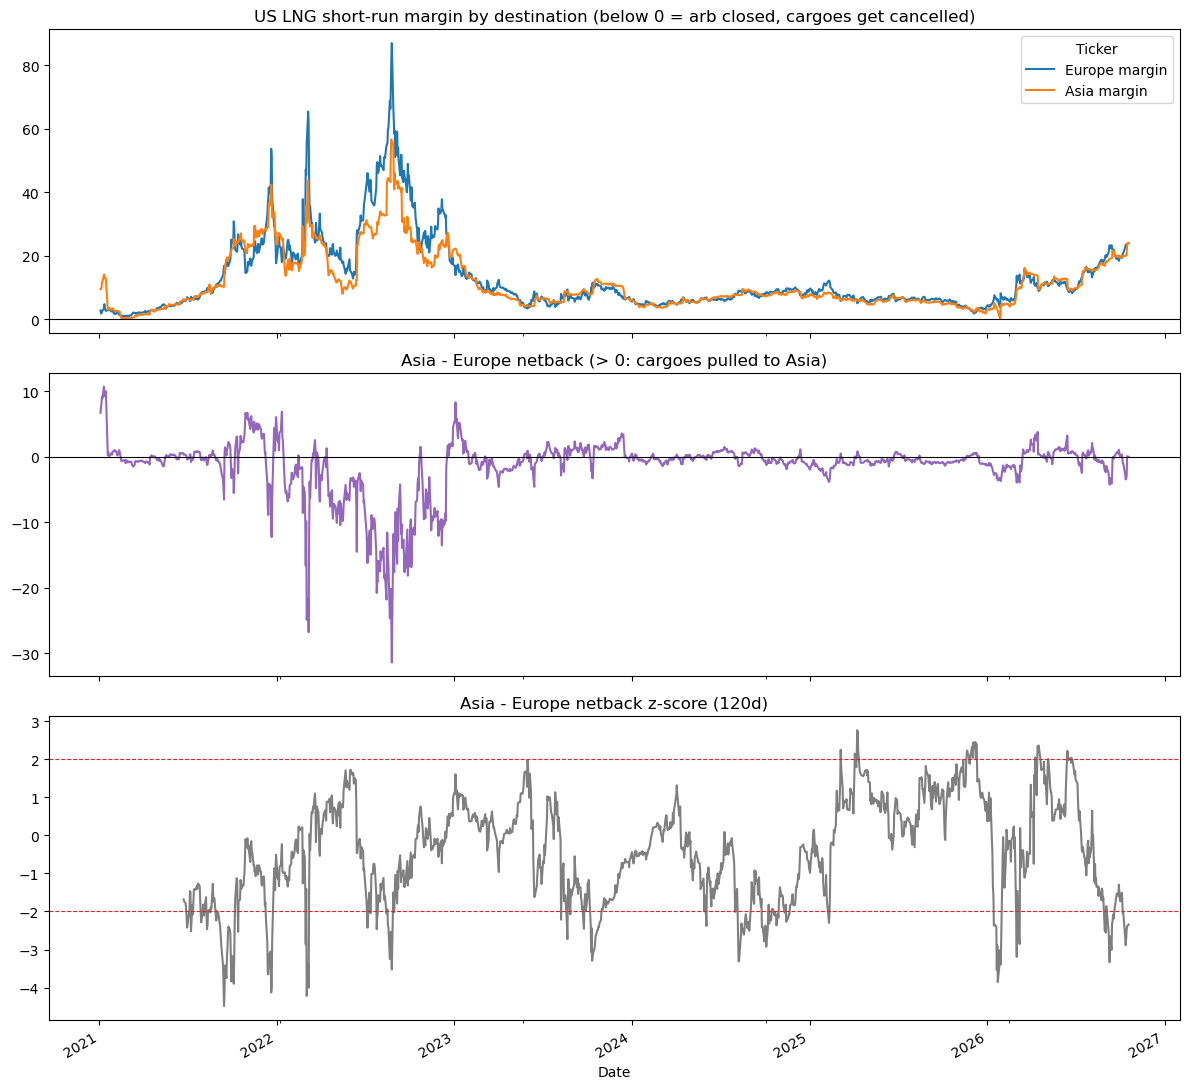

In [6]:
# Netback model: what a US LNG cargo earns delivered to Europe vs Asia (USD/MMBtu)
# Cost assumptions are rough public estimates - freight in particular swings a lot with charter rates
FEEDGAS_MULT = 1.15  # offtakers pay 115% of HH (the extra 15% is burned as fuel in liquefaction)
LIQUEFACTION_FEE = 2.50  # fixed tolling fee, sunk once the contract is signed
REGAS_EUROPE = 0.40  # regas + entry into the grid to reach TTF
SHIP_US_EUROPE = 1.00  # US Gulf -> NW Europe
SHIP_US_ASIA = 2.50  # US Gulf -> NE Asia (Cape route; Panama is cheaper when it's available)

netbacks = gas[["Henry Hub", "Dutch TTF", "JKM LNG"]].copy()
feedgas_cost = FEEDGAS_MULT * netbacks["Henry Hub"]

# Short-run margin: tolling fee is already paid, so cargoes keep lifting while this is > 0
netbacks["Europe margin"] = netbacks["Dutch TTF"] - REGAS_EUROPE - SHIP_US_EUROPE - feedgas_cost
netbacks["Asia margin"] = netbacks["JKM LNG"] - SHIP_US_ASIA - feedgas_cost
# Full-cycle margin: includes the tolling fee, i.e. is it worth building/contracting new capacity
netbacks["Europe full-cycle"] = netbacks["Europe margin"] - LIQUEFACTION_FEE
netbacks["Asia full-cycle"] = netbacks["Asia margin"] - LIQUEFACTION_FEE

# Where should the marginal US cargo go? > 0 means Asia pays more after freight
netbacks["Asia - Europe"] = netbacks["Asia margin"] - netbacks["Europe margin"]

# Mean reversion signal: when one basin pays too much, cargoes get diverted and the gap closes
# Note: Yahoo front months for JKM and TTF don't always cover the same delivery month, so this is noisy
Z_WINDOW = 120
spread = netbacks["Asia - Europe"]

# JKM=F rolls to the next contract around the 16th of each month, which shows up as fake jumps
# (>10% moves cluster on that day). Back-adjust by zeroing the spread change on roll days -
# a real position gets rolled too, so those jumps are never P&L
dates = spread.index
after_16th = pd.Series(dates.day >= 16, index=dates)
roll_day = after_16th & ~after_16th.groupby([dates.year, dates.month]).shift(1, fill_value=False)
spread_adj = spread.diff().where(~roll_day, 0).fillna(0).cumsum()

netbacks["z-score"] = (spread_adj - spread_adj.rolling(Z_WINDOW).mean()) / spread_adj.rolling(Z_WINDOW).std()

print("--- Latest netbacks (USD/MMBtu) ---")
print(netbacks.tail(5).round(2).T)

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
netbacks[["Europe margin", "Asia margin"]].plot(ax=axes[0])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("US LNG short-run margin by destination (below 0 = arb closed, cargoes get cancelled)")
spread.plot(ax=axes[1], color="tab:purple")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Asia - Europe netback (> 0: cargoes pulled to Asia)")
netbacks["z-score"].plot(ax=axes[2], color="tab:gray")
for level in (-2, 2):
    axes[2].axhline(level, color="tab:red", ls="--", lw=0.8)
axes[2].set_title(f"Asia - Europe netback z-score ({Z_WINDOW}d)")
plt.tight_layout()
plt.show()


Trades: 15, days in market: 40%, daily hit rate: 48%
Total P&L: 13.72 USD/MMBtu (x10,000 MMBtu per CME contract = $137,161 per spread)
Max drawdown: -32.16 USD/MMBtu


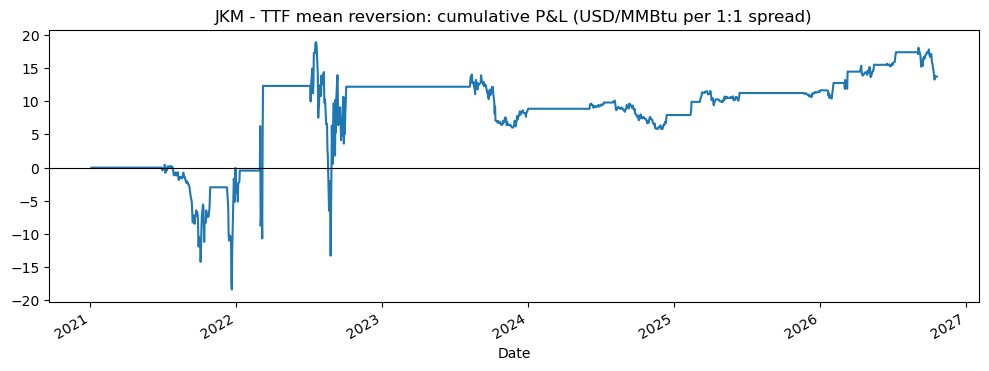

In [7]:
# Simple backtest of the mean reversion idea: trade JKM vs TTF (1:1 in USD/MMBtu)
# z > +2 -> short JKM / long TTF, z < -2 -> long JKM / short TTF, exit when |z| < 0.5
# Positions are taken the day after the signal to avoid look-ahead
ENTRY_Z, EXIT_Z = 2.0, 0.5
COST_PER_TRADE = 0.05  # USD/MMBtu round trip, both legs - roughly fees + slippage on thin JKM

position = pd.Series(0.0, index=netbacks.index)
current = 0
for date, z in netbacks["z-score"].items():
    if np.isnan(z):
        pass
    elif current == 0 and z > ENTRY_Z:
        current = -1
    elif current == 0 and z < -ENTRY_Z:
        current = 1
    elif current != 0 and abs(z) < EXIT_Z:
        current = 0
    position[date] = current

held = position.shift(1).fillna(0)
daily_pnl = held * spread_adj.diff() - position.diff().abs().shift(1).fillna(0) * COST_PER_TRADE / 2
cum_pnl = daily_pnl.cumsum()

n_trades = int((position.diff() != 0).sum() // 2)
hit_rate = (daily_pnl[held != 0] > 0).mean()
print(f"Trades: {n_trades}, days in market: {(held != 0).mean():.0%}, daily hit rate: {hit_rate:.0%}")
print(f"Total P&L: {cum_pnl.iloc[-1]:.2f} USD/MMBtu "
      f"(x10,000 MMBtu per CME contract = ${cum_pnl.iloc[-1] * 10_000:,.0f} per spread)")
print(f"Max drawdown: {(cum_pnl - cum_pnl.cummax()).min():.2f} USD/MMBtu")

cum_pnl.plot(figsize=(12, 4), title="JKM - TTF mean reversion: cumulative P&L (USD/MMBtu per 1:1 spread)")
plt.axhline(0, color="black", lw=0.8)
plt.show()


In [8]:
# EU gas storage from GIE AGSI+ - storage vs the seasonal norm is the main fundamental driver of TTF
# Needs a free API key from https://agsi.gie.eu (register -> account), then: export GIE_API_KEY=...
import os

import requests

GIE_API_KEY = os.environ.get("GIE_API_KEY")


def fetch_eu_storage(start="2016-01-01", end="2026-10-20"):
    rows, page = [], 1
    while True:
        r = requests.get(
            "https://agsi.gie.eu/api",
            params={"type": "eu", "from": start, "to": end, "size": 300, "page": page},
            headers={"x-key": GIE_API_KEY},
            timeout=30,
        )
        r.raise_for_status()
        payload = r.json()
        rows += payload["data"]
        if page >= payload["last_page"]:
            break
        page += 1
    df = pd.DataFrame(rows)
    df.index = pd.to_datetime(df["gasDayStart"])
    cols = ["full", "gasInStorage", "injection", "withdrawal"]  # % full, TWh, GWh/d, GWh/d
    return df[cols].apply(pd.to_numeric, errors="coerce").sort_index()


storage_dev = None
if not GIE_API_KEY:
    print("No GIE_API_KEY set - skipping EU storage. Get a free key at https://agsi.gie.eu")
else:
    storage = fetch_eu_storage()
    fill = storage["full"]

    # Seasonal norm: average fill on the same day of year over the previous 5 years
    five_yr_avg = pd.Series(np.nan, index=fill.index)
    for year in fill.index.year.unique():
        prior = fill[(fill.index.year >= year - 5) & (fill.index.year < year)]
        if prior.index.year.nunique() < 5:
            continue
        seasonal = prior.groupby(prior.index.dayofyear).mean()
        this_year = fill.index.year == year
        five_yr_avg[this_year] = seasonal.reindex(fill.index[this_year].dayofyear).values
    storage_dev = (fill - five_yr_avg).rename("Storage vs 5y avg (pp)")

    print(f"EU storage {fill.index[-1].date()}: {fill.iloc[-1]:.1f}% full, "
          f"{storage_dev.iloc[-1]:+.1f} pp vs 5-year average")

    # Does a storage deficit show up as a higher TTF / wider US-Europe margin?
    joined = pd.concat([storage_dev, netbacks[["Dutch TTF", "Europe margin"]]], axis=1).dropna()
    slope, intercept = np.polyfit(joined[storage_dev.name], joined["Dutch TTF"], 1)
    print(f"TTF vs storage deviation: {slope:+.2f} USD/MMBtu per pp, "
          f"corr {joined.corr().loc[storage_dev.name, 'Dutch TTF']:.2f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    fill.loc["2021":].plot(ax=axes[0], label="EU storage % full")
    five_yr_avg.loc["2021":].plot(ax=axes[0], ls="--", label="5-year average")
    axes[0].legend()
    axes[0].set_title("EU gas storage")
    axes[1].scatter(joined[storage_dev.name], joined["Dutch TTF"], s=4, alpha=0.4)
    axes[1].set_xlabel("Storage vs 5y avg (pp)")
    axes[1].set_ylabel("TTF (USD/MMBtu)")
    axes[1].set_title("Lower storage -> higher TTF?")
    plt.tight_layout()
    plt.show()


No GIE_API_KEY set - skipping EU storage. Get a free key at https://agsi.gie.eu


In [9]:
# Signal summary - latest reading of everything above
latest = netbacks.iloc[-1]
print(f"--- LNG signals as of {netbacks.index[-1].date()} ---")
print(f"HH {latest['Henry Hub']:.2f} | TTF {latest['Dutch TTF']:.2f} | JKM {latest['JKM LNG']:.2f} USD/MMBtu")
for basin in ("Europe", "Asia"):
    m = latest[f"{basin} margin"]
    print(f"US -> {basin}: margin {m:+.2f} -> arb {'OPEN' if m > 0 else 'CLOSED'} "
          f"(full-cycle {latest[f'{basin} full-cycle']:+.2f})")

z = latest["z-score"]
print(f"Asia - Europe netback {latest['Asia - Europe']:+.2f}, z-score {z:+.2f} -> ", end="")
if z > ENTRY_Z:
    print("Asia rich vs Europe: short JKM / long TTF")
elif z < -ENTRY_Z:
    print("Europe rich vs Asia: long JKM / short TTF")
else:
    print("no trade")

if storage_dev is not None:
    dev = storage_dev.dropna().iloc[-1]
    print(f"EU storage {dev:+.1f} pp vs 5y avg -> {'tight, supportive for TTF' if dev < 0 else 'comfortable, bearish for TTF'}")


--- LNG signals as of 2026-10-19 ---
HH 3.06 | TTF 28.91 | JKM 30.01 USD/MMBtu
US -> Europe: margin +23.99 -> arb OPEN (full-cycle +21.49)
US -> Asia: margin +23.99 -> arb OPEN (full-cycle +21.49)
Asia - Europe netback -0.00, z-score -2.34 -> Europe rich vs Asia: long JKM / short TTF
